In [1]:
import torch
print("GPU available:", torch.cuda.is_available())

GPU available: True


In [2]:
import os
print(os.listdir("/content"))

['.config', 'tfidf_test_proba.npy', 'tfidf_valid_proba.npy', 'cleaned_dataset.csv', 'sample_data']


In [3]:
import pandas as pd, numpy as np, torch
from transformers import AutoTokenizer, AutoModel

df = pd.read_csv("cleaned_dataset.csv")
train = df[df["split"] == "train"].reset_index(drop=True)
valid = df[df["split"] == "valid"].reset_index(drop=True)
test  = df[df["split"] == "test"].reset_index(drop=True)
print(train.shape, valid.shape, test.shape)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
bert = AutoModel.from_pretrained("distilbert-base-uncased").to(device)
bert.eval()
print("Model loaded")

(10223, 9) (1284, 9) (1267, 9)
Using: cuda


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded


In [4]:
from tqdm.auto import tqdm

def embed(texts, batch_size=64):
    all_vecs = []
    for i in tqdm(range(0, len(texts), batch_size)):
        batch = texts[i:i + batch_size]
        enc = tokenizer(batch, padding=True, truncation=True, max_length=64, return_tensors="pt").to(device)
        with torch.no_grad():
            out = bert(**enc).last_hidden_state          # (batch, tokens, 768)
        mask = enc["attention_mask"].unsqueeze(-1)       # ignore padding
        mean = (out * mask).sum(1) / mask.sum(1)         # average over real tokens
        all_vecs.append(mean.cpu().numpy())
    return np.vstack(all_vecs)

E_train = embed(train["clean"].astype(str).tolist())
E_valid = embed(valid["clean"].astype(str).tolist())
E_test  = embed(test["clean"].astype(str).tolist())

print(E_train.shape, E_valid.shape, E_test.shape)

np.save("E_train.npy", E_train)
np.save("E_valid.npy", E_valid)
np.save("E_test.npy", E_test)
print("saved")

  0%|          | 0/160 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

(10223, 768) (1284, 768) (1267, 768)
saved


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

scaler = StandardScaler().fit(E_train)
Xtr, Xva, Xte = scaler.transform(E_train), scaler.transform(E_valid), scaler.transform(E_test)

best_C, best_acc = None, 0
for C in [0.001, 0.005, 0.01, 0.05, 0.1]:
    m = LogisticRegression(C=C, max_iter=2000)
    m.fit(Xtr, train["target"])
    acc = accuracy_score(valid["target"], m.predict(Xva))
    print("C =", C, "-> validation accuracy:", round(acc, 4))
    if acc > best_acc:
        best_C, best_acc = C, acc

print("Best C:", best_C)

bert_model = LogisticRegression(C=best_C, max_iter=2000)
bert_model.fit(Xtr, train["target"])
bert_pred = bert_model.predict(Xte)

print("BERT TEST accuracy:", round(accuracy_score(test["target"], bert_pred), 4))
print("Always-guess-real baseline:", round(test["target"].mean(), 4))
print(classification_report(test["target"], bert_pred, target_names=["Fake", "Real"]))

np.save("bert_valid_proba.npy", bert_model.predict_proba(Xva)[:, 1])
np.save("bert_test_proba.npy", bert_model.predict_proba(Xte)[:, 1])
print("saved")

C = 0.001 -> validation accuracy: 0.6285
C = 0.005 -> validation accuracy: 0.6308
C = 0.01 -> validation accuracy: 0.6192
C = 0.05 -> validation accuracy: 0.6106
C = 0.1 -> validation accuracy: 0.6083
Best C: 0.005
BERT TEST accuracy: 0.6322
Always-guess-real baseline: 0.5635
              precision    recall  f1-score   support

        Fake       0.60      0.46      0.52       553
        Real       0.65      0.77      0.70       714

    accuracy                           0.63      1267
   macro avg       0.62      0.61      0.61      1267
weighted avg       0.63      0.63      0.62      1267

saved


In [7]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

p_tfidf_va = np.load("tfidf_valid_proba.npy")
p_tfidf_te = np.load("tfidf_test_proba.npy")
p_bert_va  = np.load("bert_valid_proba.npy")
p_bert_te  = np.load("bert_test_proba.npy")

y_va, y_te = valid["target"].values, test["target"].values

best_w, best_acc = 0, 0
for w in [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:   # w = weight on BERT
    p = w * p_bert_va + (1 - w) * p_tfidf_va
    acc = accuracy_score(y_va, (p >= 0.5).astype(int))
    print("BERT weight", w, "-> validation accuracy:", round(acc, 4))
    if acc > best_acc:
        best_w, best_acc = w, acc
print("Best BERT weight:", best_w)

p_ens_te = best_w * p_bert_te + (1 - best_w) * p_tfidf_te
np.save("ens_test_proba.npy", p_ens_te)

rows = []
for name, p in [("TF-IDF + LogReg", p_tfidf_te), ("DistilBERT + LogReg", p_bert_te), ("Ensemble", p_ens_te)]:
    pred = (p >= 0.5).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y_te, pred, average="macro")
    rows.append([name, accuracy_score(y_te, pred), pr, rc, f1])

results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro precision", "Macro recall", "Macro F1"]).round(4)
results.to_csv("results_table.csv", index=False)
results

BERT weight 0 -> validation accuracy: 0.6231
BERT weight 0.1 -> validation accuracy: 0.6285
BERT weight 0.2 -> validation accuracy: 0.6417
BERT weight 0.3 -> validation accuracy: 0.6316
BERT weight 0.4 -> validation accuracy: 0.634
BERT weight 0.5 -> validation accuracy: 0.6394
BERT weight 0.6 -> validation accuracy: 0.6355
BERT weight 0.7 -> validation accuracy: 0.6379
BERT weight 0.8 -> validation accuracy: 0.6293
BERT weight 0.9 -> validation accuracy: 0.6301
BERT weight 1.0 -> validation accuracy: 0.6308
Best BERT weight: 0.2


,Model,Accuracy,Macro precision,Macro recall,Macro F1
0,TF-IDF + LogReg,0.6212,0.6172,0.5927,0.5839
1,DistilBERT + LogReg,0.6322,0.6249,0.6127,0.6114
2,Ensemble,0.6409,0.6414,0.6137,0.6074


In [8]:
!pip install -q lime

from lime.lime_text import LimeTextExplainer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# rebuild the TF-IDF model here (same settings as on your laptop)
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=20000, stop_words="english", min_df=2)
Xtr_t = tfidf.fit_transform(train["clean"].astype(str))
tfidf_model = LogisticRegression(C=0.5, max_iter=1000).fit(Xtr_t, train["target"])

W = 0.2   # BERT weight chosen in Step 13

def predict_proba(texts):
    texts = list(texts)
    p_t = tfidf_model.predict_proba(tfidf.transform(texts))[:, 1]
    vecs = []
    for i in range(0, len(texts), 64):
        enc = tokenizer(texts[i:i+64], padding=True, truncation=True, max_length=64, return_tensors="pt").to(device)
        with torch.no_grad():
            out = bert(**enc).last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1)
        vecs.append(((out * mask).sum(1) / mask.sum(1)).cpu().numpy())
    p_b = bert_model.predict_proba(scaler.transform(np.vstack(vecs)))[:, 1]
    p = W * p_b + (1 - W) * p_t
    return np.column_stack([1 - p, p])

explainer = LimeTextExplainer(class_names=["Fake", "Real"], random_state=42)

i = 0
text = test["clean"].astype(str).iloc[i]
print("Statement:", text)
print("True label:", test["label"].iloc[i], "| target:", test["target"].iloc[i])
print("Model P(Real):", round(predict_proba([text])[0, 1], 3))

exp = explainer.explain_instance(text, predict_proba, num_features=8, num_samples=300)
print(exp.as_list())
exp.save_to_file("lime_example0.html")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Statement: building a wall on the u.s.-mexico border will take literally years.
True label: true | target: 1
Model P(Real): 0.489
[(np.str_('building'), -0.06879313471524096), (np.str_('border'), -0.04425682218377835), (np.str_('years'), 0.029965345674162425), (np.str_('mexico'), 0.029518984329199416), (np.str_('literally'), 0.023516351961453606), (np.str_('u'), -0.022281994421789988), (np.str_('s'), -0.021411934115159934), (np.str_('wall'), 0.010299716066096766)]


In [9]:
import matplotlib.pyplot as plt, zipfile
from google.colab import files

pred_ens = (p_ens_te >= 0.5).astype(int)
y_te = test["target"].values

idx_correct = [i for i in np.where((pred_ens == y_te) & (np.abs(p_ens_te - 0.5) > 0.1))[0]][:2]
idx_wrong = [i for i in np.where(pred_ens != y_te)[0] if i != 0][:2]
indices = [0] + idx_correct + idx_wrong
tags = ["uncertain_wrong"] + ["correct"] * len(idx_correct) + ["wrong"] * len(idx_wrong)

saved = []
for i, tag in zip(indices, tags):
    text = test["clean"].astype(str).iloc[i]
    exp = explainer.explain_instance(text, predict_proba, num_features=8, num_samples=300)
    fig = exp.as_pyplot_figure()
    fig.suptitle(tag + ": " + text[:70], fontsize=9)
    name = f"lime_{i}_{tag}.png"
    fig.savefig(name, dpi=150, bbox_inches="tight")
    plt.close(fig)
    saved.append(name)
    print(tag, "| index", i, "| true:", test["label"].iloc[i], "| P(Real):", round(p_ens_te[i], 3))
    print("   ", text)
    print("   ", [(w, round(s, 3)) for w, s in exp.as_list()])

with zipfile.ZipFile("lime_figures.zip", "w") as z:
    for n in saved:
        z.write(n)
files.download("lime_figures.zip")

uncertain_wrong | index 0 | true: true | P(Real): 0.489
    building a wall on the u.s.-mexico border will take literally years.
    [(np.str_('building'), -0.064), (np.str_('border'), -0.039), (np.str_('years'), 0.037), (np.str_('mexico'), 0.031), (np.str_('literally'), 0.029), (np.str_('s'), -0.022), (np.str_('u'), -0.02), (np.str_('take'), -0.008)]
correct | index 4 | true: pants-fire | P(Real): 0.354
    when asked by a reporter whether hes at the center of a criminal scheme to violate campaign laws, gov. scott walker nodded yes.
    [(np.str_('scott'), -0.083), (np.str_('walker'), -0.078), (np.str_('scheme'), -0.035), (np.str_('hes'), 0.034), (np.str_('gov'), -0.033), (np.str_('center'), 0.017), (np.str_('yes'), 0.016), (np.str_('violate'), 0.012)]
correct | index 6 | true: true | P(Real): 0.627
    says that tennessee law requires that schools receive half of proceeds -- $31 million per year -- from a half-cent increase in the shelby county sales tax.
    [(np.str_('half'), 0.084

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

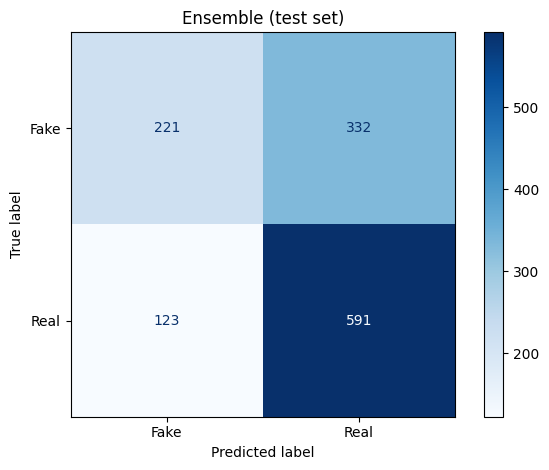

              precision    recall  f1-score   support

        Fake       0.64      0.40      0.49       553
        Real       0.64      0.83      0.72       714

    accuracy                           0.64      1267
   macro avg       0.64      0.61      0.61      1267
weighted avg       0.64      0.64      0.62      1267



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from google.colab import files

pred_ens = (p_ens_te >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(
    test["target"], pred_ens, display_labels=["Fake", "Real"], cmap="Blues"
)
plt.title("Ensemble (test set)")
plt.tight_layout()
plt.savefig("chart_confusion_ensemble.png", dpi=150)
plt.show()

print(classification_report(test["target"], pred_ens, target_names=["Fake", "Real"]))

files.download("chart_confusion_ensemble.png")
files.download("results_table.csv")

Statement : Says John McCain has done nothing to help the vets.
Prediction: REAL (P(real) = 0.51, confidence = 51%)
Note      : LOW CONFIDENCE, treat this as uncertain.


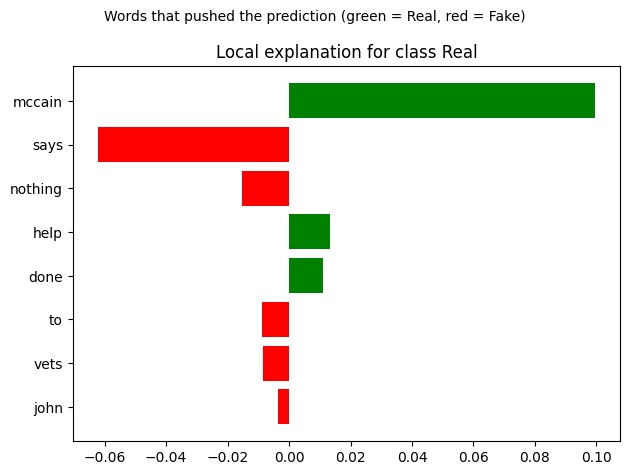

and must not be used to flag political content without human review.


In [7]:
import matplotlib.pyplot as plt

def check(statement):
    text = statement.lower().strip()
    p_real = predict_proba([text])[0, 1]
    label = "REAL" if p_real >= 0.5 else "FAKE"
    confidence = max(p_real, 1 - p_real)

    print("=" * 60)
    print("Statement :", statement)
    print("Prediction:", label, f"(P(real) = {p_real:.2f}, confidence = {confidence:.0%})")
    if confidence < 0.60:
        print("Note      : LOW CONFIDENCE, treat this as uncertain.")

    exp = explainer.explain_instance(text, predict_proba, num_features=8, num_samples=300)
    fig = exp.as_pyplot_figure()
    fig.suptitle("Words that pushed the prediction (green = Real, red = Fake)", fontsize=10)
    plt.tight_layout()
    plt.show()

    print("WARNING: This tool assists human review only. It does not verify facts")
    print("and must not be used to flag political content without human review.")
    print("=" * 60)

check("Says John McCain has done nothing to help the vets.")

In [6]:
import os
import pandas as pd, numpy as np, torch
from transformers import AutoTokenizer, AutoModel
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

if not os.path.exists("cleaned_dataset.csv"):
    raise SystemExit("cleaned_dataset.csv is missing. Upload it with the folder icon on the left, then run this cell again.")

!pip install -q lime
from lime.lime_text import LimeTextExplainer

df = pd.read_csv("cleaned_dataset.csv")
train = df[df["split"] == "train"].reset_index(drop=True)
valid = df[df["split"] == "valid"].reset_index(drop=True)
test  = df[df["split"] == "test"].reset_index(drop=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
bert = AutoModel.from_pretrained("distilbert-base-uncased").to(device)
bert.eval()

def embed(texts, batch_size=64):
    vecs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=64, return_tensors="pt").to(device)
        with torch.no_grad():
            out = bert(**enc).last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1)
        vecs.append(((out * mask).sum(1) / mask.sum(1)).cpu().numpy())
    return np.vstack(vecs)

if os.path.exists("E_train.npy"):
    E_train = np.load("E_train.npy")
else:
    E_train = embed(train["clean"].astype(str).tolist())
    np.save("E_train.npy", E_train)

scaler = StandardScaler().fit(E_train)
bert_model = LogisticRegression(C=0.005, max_iter=2000).fit(scaler.transform(E_train), train["target"])

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=20000, stop_words="english", min_df=2)
Xtr_t = tfidf.fit_transform(train["clean"].astype(str))
tfidf_model = LogisticRegression(C=0.5, max_iter=1000).fit(Xtr_t, train["target"])

W = 0.2

def predict_proba(texts):
    texts = list(texts)
    p_t = tfidf_model.predict_proba(tfidf.transform(texts))[:, 1]
    p_b = bert_model.predict_proba(scaler.transform(embed(texts)))[:, 1]
    p = W * p_b + (1 - W) * p_t
    return np.column_stack([1 - p, p])

explainer = LimeTextExplainer(class_names=["Fake", "Real"], random_state=42)
print("Restored. You can now run the check(...) cell again.")

Using: cuda


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Restored. You can now run the check(...) cell again.
